# Predicting House Prices with Linear Regression
**Oasis Infobyte SIP — Data Analytics L2 Task 1** · Steven Manuel Rios

Dataset: **Ames Housing** (De Cock, 2011): 2,930 home sales in Ames, Iowa, 2006–2010, with 80 features.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
def save(name): plt.tight_layout(); plt.savefig(f"screenshots/{name}.png", dpi=110); plt.show()

In [2]:
df = pd.read_csv("data/ames_housing.csv").drop(columns=["Unnamed: 0", "Order", "PID"])
print(df.shape); df["SalePrice"].describe()

(2930, 80)


count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [3]:
nulls = df.isnull().sum(); nulls[nulls > 0].sort_values(ascending=False).head(15)

Pool QC           2917
Misc Feature      2824
Alley             2732
Fence             2358
Mas Vnr Type      1775
Fireplace Qu      1422
Lot Frontage       490
Garage Qual        159
Garage Cond        159
Garage Yr Blt      159
Garage Finish      159
Garage Type        157
Bsmt Exposure       83
BsmtFin Type 2      81
Bsmt Cond           80
dtype: int64

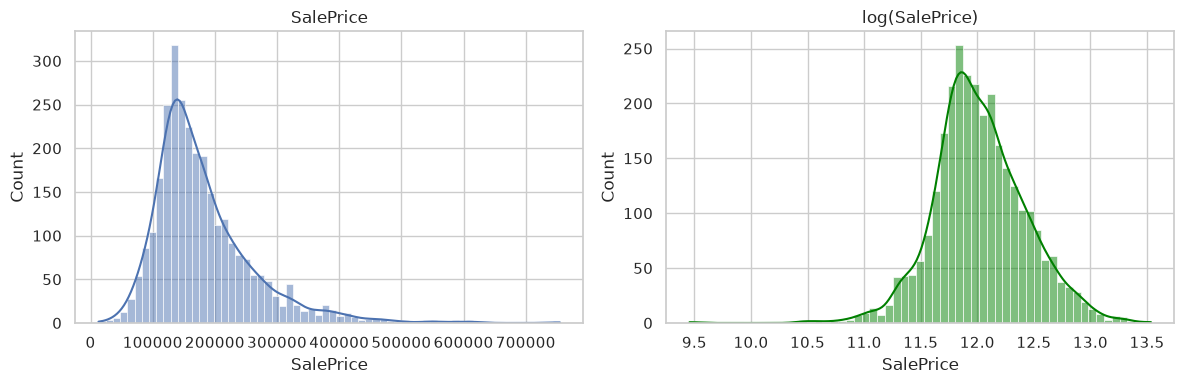

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4)); sns.histplot(df.SalePrice, kde=True, ax=ax[0]); ax[0].set_title("SalePrice")
sns.histplot(np.log(df.SalePrice), kde=True, ax=ax[1], color="green"); ax[1].set_title("log(SalePrice)"); save("target_distribution")

The price is right-skewed (mean ≈ \$181k, median \$160k). A log transform makes it near-normal, which suits linear regression's assumption of normally distributed errors, so the model is trained on **log(price)**. Metrics are reported back in dollars.

## Feature selection discussion
Likely predictors, based on domain knowledge:
* **Size:** `Gr Liv Area`, `Total Bsmt SF`, `Garage Area`/`Garage Cars`, `Lot Area`
* **Quality:** `Overall Qual`, `Kitchen Qual`, `Exter Qual`
* **Age:** `Year Built` and `Year Remod/Add`, turned into a house age
* **Rooms:** `Full Bath`, `Bedroom AbvGr`, `TotRms AbvGrd`, `Fireplaces`
* **Location:** `Neighborhood`, one-hot encoded, since location is a major price driver

Mostly-empty columns (Pool QC, Misc Feature, Alley, Fence) and near-constant ones are dropped. The heatmap below checks these choices.

In [5]:
df["HouseAge"] = df["Yr Sold"] - df["Year Built"]; df["RemodAge"] = df["Yr Sold"] - df["Year Remod/Add"]
qual_map = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1}
for col in ["Kitchen Qual", "Exter Qual", "Bsmt Qual"]: df[col] = df[col].map(qual_map).fillna(0)
num = ["Overall Qual", "Gr Liv Area", "Total Bsmt SF", "Garage Cars", "Garage Area", "Lot Area", "Full Bath", "Half Bath", "Bedroom AbvGr", "TotRms AbvGrd", "Fireplaces", "HouseAge", "RemodAge", "Kitchen Qual", "Exter Qual", "Bsmt Qual", "Mas Vnr Area", "Overall Cond"]
cat = ["Neighborhood", "MS Zoning", "Bldg Type", "Central Air"]
data = df[num + cat + ["SalePrice"]].copy()
for col in num: data[col] = data[col].fillna(data[col].median())   # median: robust for skewed areas
for col in cat: data[col] = data[col].fillna(data[col].mode()[0])
# remove the documented extreme partial-sale outliers (>4000 sq ft, < $300k), as recommended by De Cock
data = data[~((data["Gr Liv Area"] > 4000) & (data.SalePrice < 300000))]
print(data.isnull().sum().sum(), data.shape)

0 (2927, 23)


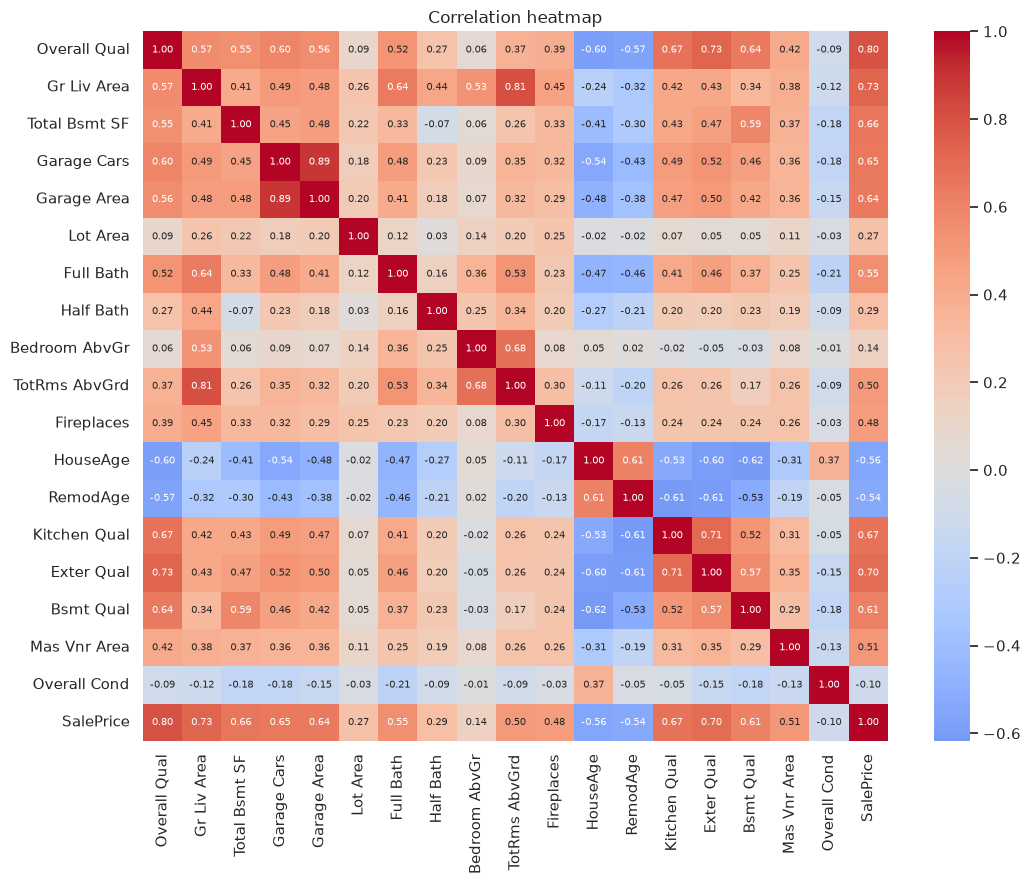

Overall Qual     0.803
Gr Liv Area      0.727
Exter Qual       0.701
Kitchen Qual     0.675
Total Bsmt SF    0.660
Garage Cars      0.648
Garage Area      0.644
Bsmt Qual        0.609
Full Bath        0.546
Mas Vnr Area     0.508
TotRms AbvGrd    0.500
Fireplaces       0.476
Half Bath        0.285
Lot Area         0.271
Bedroom AbvGr    0.144
Overall Cond    -0.102
RemodAge        -0.535
HouseAge        -0.559
Name: SalePrice, dtype: float64

In [6]:
plt.figure(figsize=(11, 9)); corr = data[num + ["SalePrice"]].corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}); plt.title("Correlation heatmap"); save("correlation")
corr["SalePrice"].drop("SalePrice").sort_values(ascending=False).round(3)

In [7]:
X = pd.get_dummies(data.drop(columns="SalePrice"), columns=cat, drop_first=True, dtype=float); y = np.log(data.SalePrice)
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, random_state=42); X.shape

(2927, 56)

In [8]:
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler; from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
models = {"Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
          "Ridge (CV)": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))),
          "Lasso (CV)": make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0, max_iter=20000))}
rows = {}; preds = {}
for n, m in models.items():
    m.fit(Xtr, ytr); p = np.exp(m.predict(Xte)); preds[n] = p; a = np.exp(yte)
    mse = mean_squared_error(a, p); rows[n] = {"MSE": mse, "RMSE ($)": np.sqrt(mse), "R² ($)": r2_score(a, p), "R² (log)": r2_score(yte, np.log(p))}
res = pd.DataFrame(rows).T; res.style.format({"MSE": "{:.3e}", "RMSE ($)": "{:,.0f}", "R² ($)": "{:.4f}", "R² (log)": "{:.4f}"})

,MSE,RMSE ($),R² ($),R² (log)
Linear Regression,4.922e+08,"22,186",0.9389,0.9356
Ridge (CV),4.808e+08,"21,926",0.9403,0.9353
Lasso (CV),4.903e+08,"22,144",0.9392,0.9353


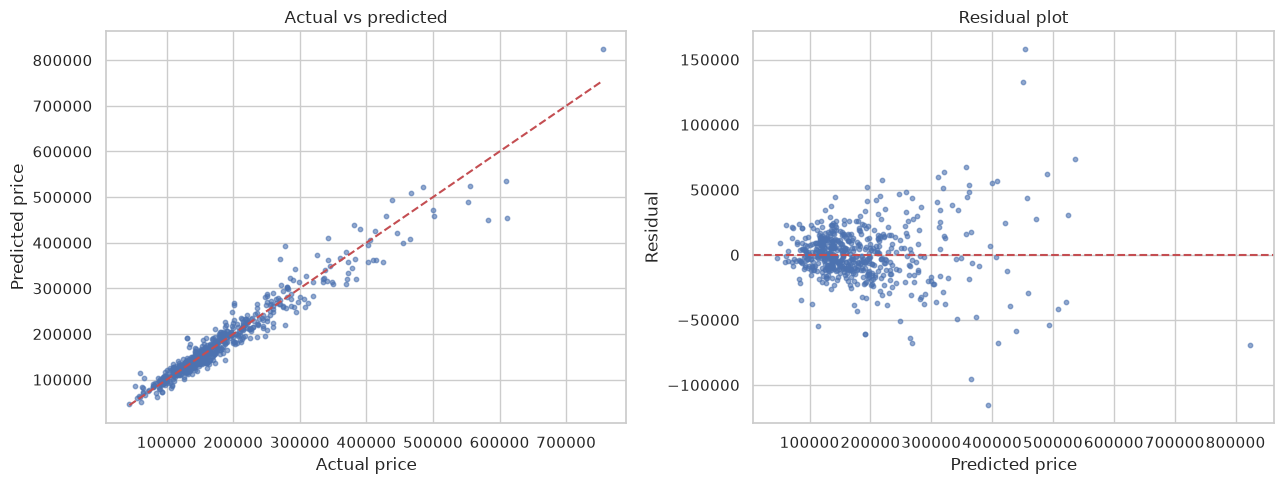

In [9]:
a = np.exp(yte); p = preds["Linear Regression"]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(a, p, s=10, alpha=.6); ax[0].plot([a.min(), a.max()], [a.min(), a.max()], "r--"); ax[0].set_xlabel("Actual price"); ax[0].set_ylabel("Predicted price"); ax[0].set_title("Actual vs predicted")
ax[1].scatter(p, a - p, s=10, alpha=.6); ax[1].axhline(0, color="r", ls="--"); ax[1].set_xlabel("Predicted price"); ax[1].set_ylabel("Residual"); ax[1].set_title("Residual plot")
save("actual_vs_pred_residuals")

## Coefficient analysis
The features are standardised, so each coefficient is the change in **log price per 1 standard deviation**. ×100 gives roughly the % change in price.

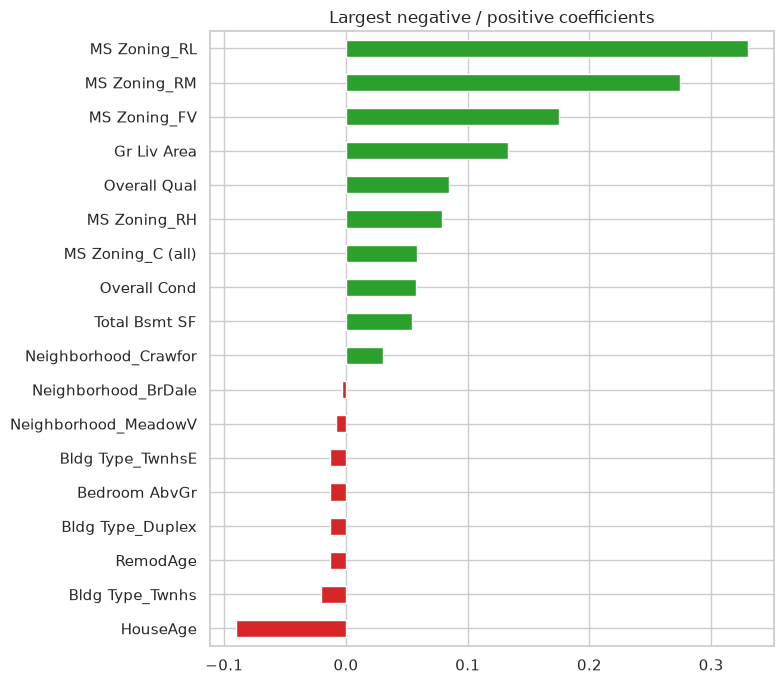

(MS Zoning_RL            0.3305
 MS Zoning_RM            0.2741
 MS Zoning_FV            0.1747
 Gr Liv Area             0.1334
 Overall Qual            0.0848
 MS Zoning_RH            0.0790
 MS Zoning_C (all)       0.0581
 Overall Cond            0.0572
 Total Bsmt SF           0.0540
 Neighborhood_Crawfor    0.0304
 dtype: float64,
 HouseAge               -0.0907
 Bldg Type_Twnhs        -0.0208
 RemodAge               -0.0135
 Bldg Type_Duplex       -0.0133
 Bedroom AbvGr          -0.0131
 Bldg Type_TwnhsE       -0.0129
 Neighborhood_MeadowV   -0.0080
 Neighborhood_BrDale    -0.0035
 dtype: float64)

In [10]:
coef = pd.Series(models["Linear Regression"][-1].coef_, index=X.columns).sort_values()
top = pd.concat([coef.head(8), coef.tail(10)])
top.plot.barh(figsize=(8, 7), color=["#d62728" if v < 0 else "#2ca02c" for v in top]); plt.title("Largest negative / positive coefficients"); save("coefficients")
coef.tail(10)[::-1].round(4), coef.head(8).round(4)

## Interpretation & conclusion
**Performance (test set, 586 homes):** Linear Regression reaches **R² = 0.939** in dollars, with RMSE ≈ **\$22.2k** (≈12% of the mean price). Actual vs predicted points sit tightly on the diagonal. The residuals look randomly scattered around zero, with slightly more spread for expensive homes (mild heteroscedasticity, already reduced by the log target).

**Coefficients (standardised, log-price):**
* **Positive:** living area (`Gr Liv Area`, +13% per SD), `Overall Qual` (+8.5%), `Overall Cond`, basement size, and premium neighbourhoods such as Crawford.
* **Negative:** `HouseAge` (−9% per SD), townhouse and duplex building types, bedroom count *at fixed living area* (more, smaller rooms are worth less), and neighbourhoods like Meadow Village and Briardale.
* The large `MS Zoning_*` coefficients are a **baseline artefact**. The reference categories (agricultural/industrial) have only 4 homes, so every residential zone looks strongly positive compared with them. Read them as \"residential zoning vs. non-residential\", not as standalone effects.

**Bonus, regularisation:** Ridge (R² 0.940, RMSE \$21.9k) is marginally better than plain OLS and Lasso (0.939). With 2,900 rows and 55 features there is little overfitting to fix, but Ridge does stabilise the correlated coefficients (garage cars and area, the quality scores).